# ExLightNet: cached CPU reproduction and statistics

The default scope is the completed full CPU reproduction. This notebook reads persisted results, predictions-derived tables and benchmark evidence. It never launches training, test inference or a benchmark. Historical reduced-run evidence appears in its own Fast demonstration section. Paper values are labelled quotations.

## 0. Environment

Restart and run all to inspect the cached analysis. RUN_MODE defaults to full.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "src/exlightnet").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("MPLCONFIGDIR", "/tmp/exlightnet-mpl")
RUN_MODE = os.environ.get("EXLIGHTNET_RUN_MODE", "full")
from IPython.display import display
import pandas as pd
from exlightnet.bench import environment_info
from exlightnet.io import read_json
from exlightnet.preprocess import FlowPreprocessor
from exlightnet import notebook as presentation
display(environment_info())
print("This analysis runs on the CPU. The displayed library versions and processor describe the current environment.")

{'platform': 'Linux-6.1.0-56-amd64-x86_64-with-glibc2.36',
 'cpu': 'Intel(R) Core(TM) i5-8500 CPU @ 3.00GHz',
 'python': '3.11.2',
 'versions': {'numpy': '1.26.4',
  'pandas': '2.2.3',
  'scipy': '1.14.1',
  'torch': '2.6.0+cpu',
  'scikit-learn': '1.6.1',
  'xgboost-cpu': '2.1.4',
  'shap': '0.46.0',
  'nbformat': '5.10.4',
  'nbconvert': '7.16.6',
  'pytest': '8.3.5'},
 'cuda_used': False,
 'torch_threads': 1,
 'torch_interop_threads': 6,
 'threadpools': [{'api': 'openmp', 'library': 'openmp', 'threads': 1},
  {'api': 'openmp', 'library': 'openmp', 'threads': 1},
  {'api': 'blas', 'library': 'openblas', 'threads': 1},
  {'api': 'blas', 'library': 'openblas', 'threads': 1}]}

This analysis runs on the CPU. The displayed library versions and processor describe the current environment.


## 1. Data and D1/D2

Gate evidence comes from the genuine corpus and its persisted class-stratified partition.

In [2]:
gates = read_json(ROOT / "results/data_gates.json")
display(pd.DataFrame(gates))
print("D1/D2 status is read from saved row counts, split sizes and class supports. This notebook does not rewrite gates or rebuild data caches.")

,gate,pass,actual
0,D1,True,"{'rows': 123117, 'counts': {'mqtt_publish': 41..."
1,D2,True,"{'sizes': {'train': 86181, 'val': 18468, 'test..."


D1/D2 status is read from saved row counts, split sizes and class supports. This notebook does not rewrite gates or rebuild data caches.


## 2. Train-only preprocessing and MI

Feature identity follows descending MI order; category vocabularies and all fitted statistics remain frozen from training.

In [3]:
pp = FlowPreprocessor.load(ROOT / "artifacts")
display(pp.compare_table4())
display(pd.DataFrame(pp.ranking_[:40]))
print(f"The persisted selection shares {pp.compare_table4()['overlap_count']} of 40 paper features. Ranking agreement was measured, not forced.")

{'gate': 'P1',
 'report_only': True,
 'overlap_count': 40,
 'budget': 40,
 'spearman_shared_ranks': 0.9994371482176362,
 'shared_features': ['fwd_pkts_payload.avg',
  'fwd_pkts_payload.max',
  'fwd_subflow_bytes',
  'flow_pkts_payload.tot',
  'flow_pkts_payload.std',
  'fwd_pkts_payload.tot',
  'flow_pkts_payload.avg',
  'flow_pkts_payload.max',
  'flow_iat.min',
  'bwd_subflow_bytes',
  'bwd_pkts_payload.tot',
  'bwd_pkts_payload.avg',
  'bwd_pkts_payload.max',
  'flow_iat.tot',
  'flow_iat.max',
  'flow_duration',
  'active.max',
  'active.tot',
  'active.avg',
  'fwd_iat.min',
  'payload_bytes_per_second',
  'active.min',
  'fwd_pkts_per_sec',
  'flow_pkts_per_sec',
  'fwd_iat.max',
  'bwd_pkts_per_sec',
  'fwd_iat.tot',
  'bwd_pkts_payload.std',
  'flow_iat.avg',
  'fwd_iat.avg',
  'bwd_iat.tot',
  'bwd_iat.max',
  'fwd_header_size_tot',
  'bwd_header_size_tot',
  'bwd_iat.avg',
  'flow_iat.std',
  'id.resp_p',
  'bwd_header_size_max',
  'bwd_header_size_min',
  'bwd_data_pkts_tot'

,rank,feature,mi
0,1,fwd_pkts_payload.avg,0.318111
1,2,fwd_pkts_payload.max,0.311076
2,3,fwd_subflow_bytes,0.310022
3,4,flow_pkts_payload.tot,0.307841
4,5,flow_pkts_payload.std,0.305293
5,6,fwd_pkts_payload.tot,0.305003
6,7,flow_pkts_payload.avg,0.301783
7,8,flow_pkts_payload.max,0.300659
8,9,flow_iat.min,0.298581
9,10,bwd_subflow_bytes,0.296417


The persisted selection shares 40 of 40 paper features. Ranking agreement was measured, not forced.


## 3. Architecture and M1

Conv lengths are 40 → 38 → 36 → 34; convolutions have no padding or biases.

In [4]:
from exlightnet.model import ExLightNet, model_gate
display(ExLightNet(12))
display(model_gate())
print("M1 checks constructed parameter counts for both heads and the no-SE variant; no model is trained or evaluated here.")

ExLightNet(
  (stem): Sequential(
    (0): Conv1d(1, 48, kernel_size=(3,), stride=(1,), bias=False)
    (1): BatchNorm1d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
  )
  (block1): Block(
    (conv): Sequential(
      (0): Conv1d(48, 48, kernel_size=(3,), stride=(1,), groups=48, bias=False)
      (1): Conv1d(48, 96, kernel_size=(1,), stride=(1,), bias=False)
    )
    (bn): BatchNorm1d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU()
    (se): SE(
      (pool): AdaptiveAvgPool1d(output_size=1)
      (fc1): Linear(in_features=96, out_features=24, bias=True)
      (relu): ReLU()
      (fc2): Linear(in_features=24, out_features=96, bias=True)
      (sigmoid): Sigmoid()
    )
  )
  (block2): Block(
    (conv): Sequential(
      (0): Conv1d(96, 96, kernel_size=(3,), stride=(1,), groups=96, bias=False)
      (1): Conv1d(96, 144, kernel_size=(1,), stride=(1,), bias=False)
    )
    (bn): BatchNorm1d(144, eps=1e-05, 

{'gate': 'M1',
 'pass': True,
 'actual': {'multiclass': 38328, 'binary': 35438, 'no_se': 23052},
 'stages': {'stem': 240, 'block1': 9672, 'block2': 24948, 'head': 3468}}

M1 checks constructed parameter counts for both heads and the no-SE variant; no model is trained or evaluated here.


## 4. Cached campaign and effective status

Validation-only model selection is preserved. Current status is derived alongside the unchanged historical pipeline flag.

In [5]:
manifest = presentation.experiment(ROOT, RUN_MODE)
display(manifest)
display(read_json(ROOT / "results" / RUN_MODE / "alpha_selection.json"))
presentation.show_execution_status(ROOT, RUN_MODE)
print("Archived CPU-idle failures remain evidence. A later successful benchmark recovery is reported separately; raw status files are never edited.")

{'mode': 'full',
 'seeds': [42, 43, 44, 45, 46],
 'tasks': ['binary', 'multiclass'],
 'models': ['exlightnet',
  'mlp',
  'bilstm',
  'std_cnn',
  'random_forest',
  'xgboost'],
 'fast_max_epochs': None,
 'full_five_seed_headlines_complete': True,
 'elapsed_seconds_this_invocation': 2.668104565000249,
 'failures': [],
 'optional_kd': 'not implemented (lowest priority)',
 'leakage_proxy_requested': False,
 'stage': 'aggregate_only',
 'skip_benchmark': True,
 'pid': 1010041,
 'threads': 1,
 'started_at': '2026-11-16T15:11:13.102049+00:00',
 'finished_at': '2026-11-16T15:11:15.770158+00:00',
 'source_sha256': {'preprocess.py': 'c58cbd024bca1023f104bd3a9c5ccf8979a007af262ffec808f5b3f8265d0529',
  'losses.py': 'f45d93b98bbcc210dc1ec09c264d2c06581339411ee826f0866e4b2f515f7f77',
  'quantize.py': '65042ec46b68eeb8db3ddfb38c9b08c60c288bddebf8407f0cded3cd74a4ee2b',
  'run_all.py': '5e4f831400b6e6f1b648d1d82087aff80d8dcc06d151da37664dfb5c988443de',
  '__init__.py': 'e655fc81d4f9247f9c1bb6dc2467b1

{'binary': {'chosen': 'effective_num',
  'selection_metric': 'seed42 validation macro-F1',
  'seed': 42,
  'candidates': [{'mode': 'inv_freq',
    'validation_macro_f1': 0.9421064972406856,
    'best_epoch': 7},
   {'mode': 'sqrt_inv_freq',
    'validation_macro_f1': 0.9803234429850337,
    'best_epoch': 7},
   {'mode': 'effective_num',
    'validation_macro_f1': 0.9854911138018254,
    'best_epoch': 7},
   {'mode': 'none',
    'validation_macro_f1': 0.984458429601228,
    'best_epoch': 7}],
  'sweep_max_epochs': 8,
  'tie_break': 'first in inv_freq,sqrt_inv_freq,effective_num,none',
  'test_used': False,
  'data_fingerprint': 'dfba90bd116f9288bc72a837160516984ba773b11904e98561c80cda7dedcf5c'},
 'multiclass': {'chosen': 'none',
  'selection_metric': 'seed42 validation macro-F1',
  'seed': 42,
  'candidates': [{'mode': 'inv_freq',
    'validation_macro_f1': 0.6626591114313519,
    'best_epoch': 8},
   {'mode': 'sqrt_inv_freq',
    'validation_macro_f1': 0.7718128568257825,
    'best_epo

,effective_status,raw_pipeline_status,active_failure_count,archived_idle_failure_count,latest_benchmark_campaign,latest_benchmark_measured_models,explanation
0,complete,complete_with_stopped_branches,0,2,20261117T052645467310-1050022,95,The raw pipeline flag preserves its initial CP...


,campaign,source,branch,error_type,reason,stage
0,20261116T151119336040-1010228,results/full/benchmarks/20261116T151119336040-...,benchmark/binary/exlightnet/42,IdleCPUUnavailable,CPU did not remain idle (<= 5% busy) for 3 win...,benchmark_only
1,20261117T051732374195-1034809,results/full/benchmarks/20261117T051732374195-...,benchmark/binary/exlightnet/42,IdleCPUUnavailable,CPU did not remain idle (<= 5% busy) for 3 win...,benchmark_only


Archived CPU-idle failures remain evidence. A later successful benchmark recovery is reported separately; raw status files are never edited.


## 5. Binary results

Attack is class 1; decisions use two-logit argmax at a fixed threshold. All requested seeds and seed 42 are shown.

n=5, indicative only
Tiny multiclass test supports make macro-F1 comparisons noisy: metasploit_brute_force_ssh (test n=5), nmap_fin_scan (test n=4). Training seeds do not measure split or campaign variability.


,model,n_seeds,macro_f1_mean,macro_f1_std,macro_f1_seed42,accuracy_mean,macro_recall_mean,auc_mean
0,exlightnet,5,0.987069,0.00085,0.988054,0.995289,0.986079,0.997704


Per-class table and operating point below use seed 42.


,precision,recall,f1,support
normal,0.985931,0.971215,0.978518,1876.0
attack,0.996751,0.998433,0.997591,16592.0


,attack_recall,miss_count,fp_count,fpr,threshold
0,0.998433,26,54,0.028785,0.5


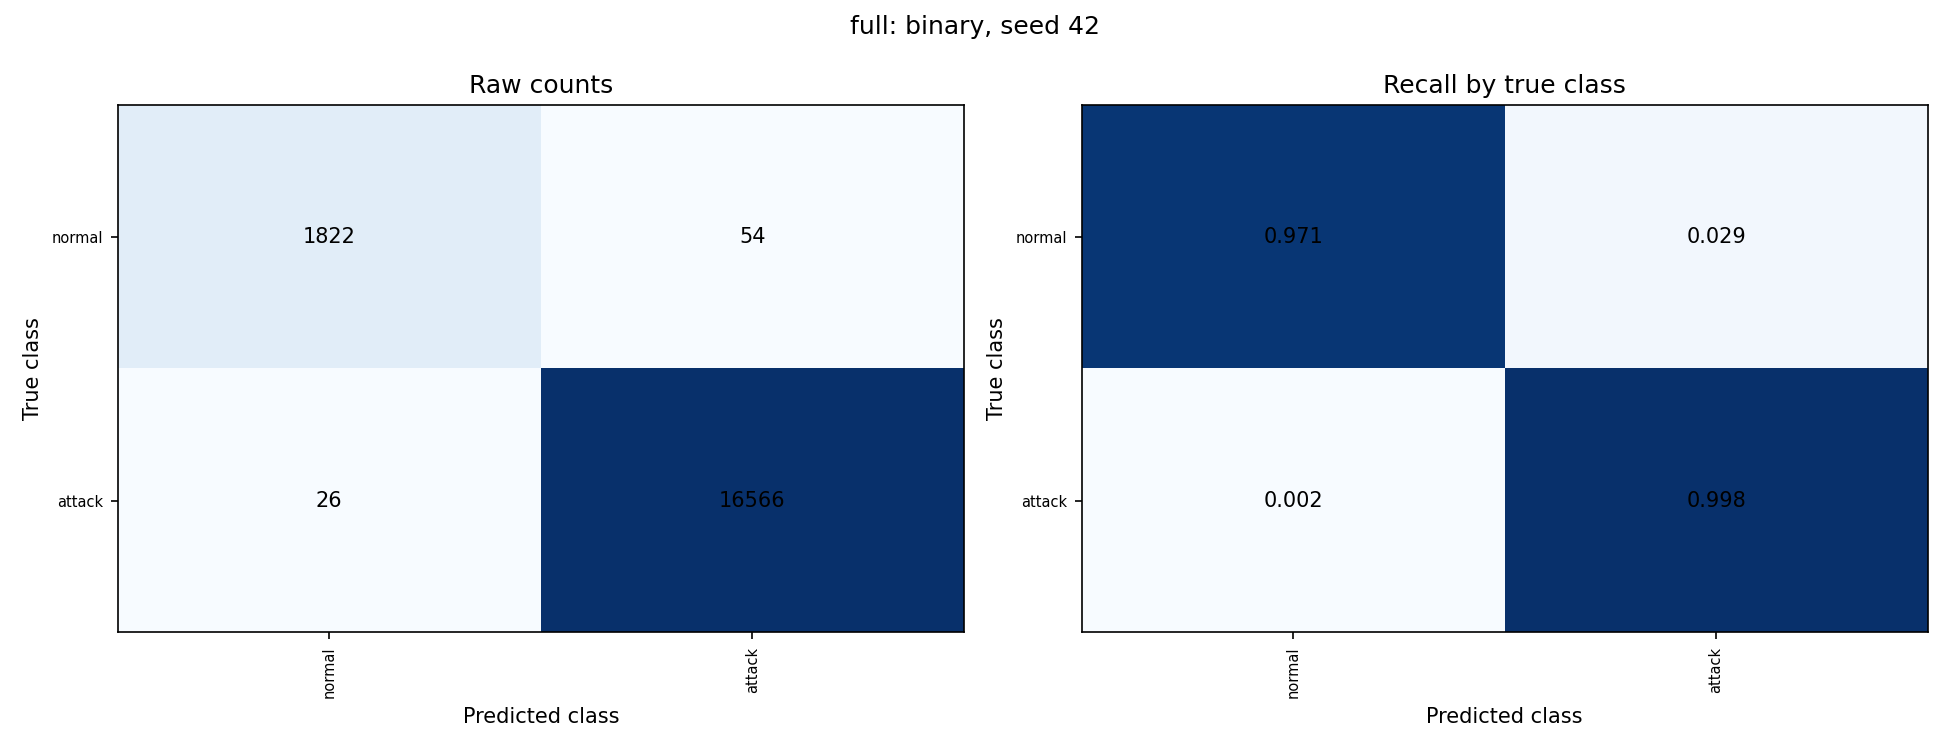

Across 5 seed(s), mean macro-F1 is 0.987069; seed 42 is 0.988054. Sample SD is 0.000850.


In [6]:
presentation.show_task(ROOT, RUN_MODE, "binary")

## 6. Twelve-class results

Per-class support accompanies every class metric. Tiny supports make macro-F1 comparisons noisy.

n=5, indicative only
Tiny multiclass test supports make macro-F1 comparisons noisy: metasploit_brute_force_ssh (test n=5), nmap_fin_scan (test n=4). Training seeds do not measure split or campaign variability.


,model,n_seeds,macro_f1_mean,macro_f1_std,macro_f1_seed42,accuracy_mean,macro_recall_mean,auc_mean
0,exlightnet,5,0.846598,0.019463,0.824796,0.976825,0.869875,0.999718


Per-class table and operating point below use seed 42.


,precision,recall,f1,support
arp_poisioning,0.933946,0.961274,0.947413,1162.0
ddos_slowloris,0.784314,1.000000,0.879121,80.0
dos_syn_hping,1.000000,1.000000,1.000000,14199.0
metasploit_brute_force_ssh,0.833333,1.000000,0.909091,5.0
mqtt_publish,1.000000,0.995177,0.997583,622.0
nmap_fin_scan,0.375000,0.750000,0.500000,4.0
nmap_os_detection,0.566406,0.483333,0.521583,300.0
nmap_tcp_scan,0.986928,1.000000,0.993421,151.0
nmap_udp_scan,0.997151,0.899743,0.945946,389.0
nmap_xmas_tree_scan,0.545455,0.615894,0.578538,302.0


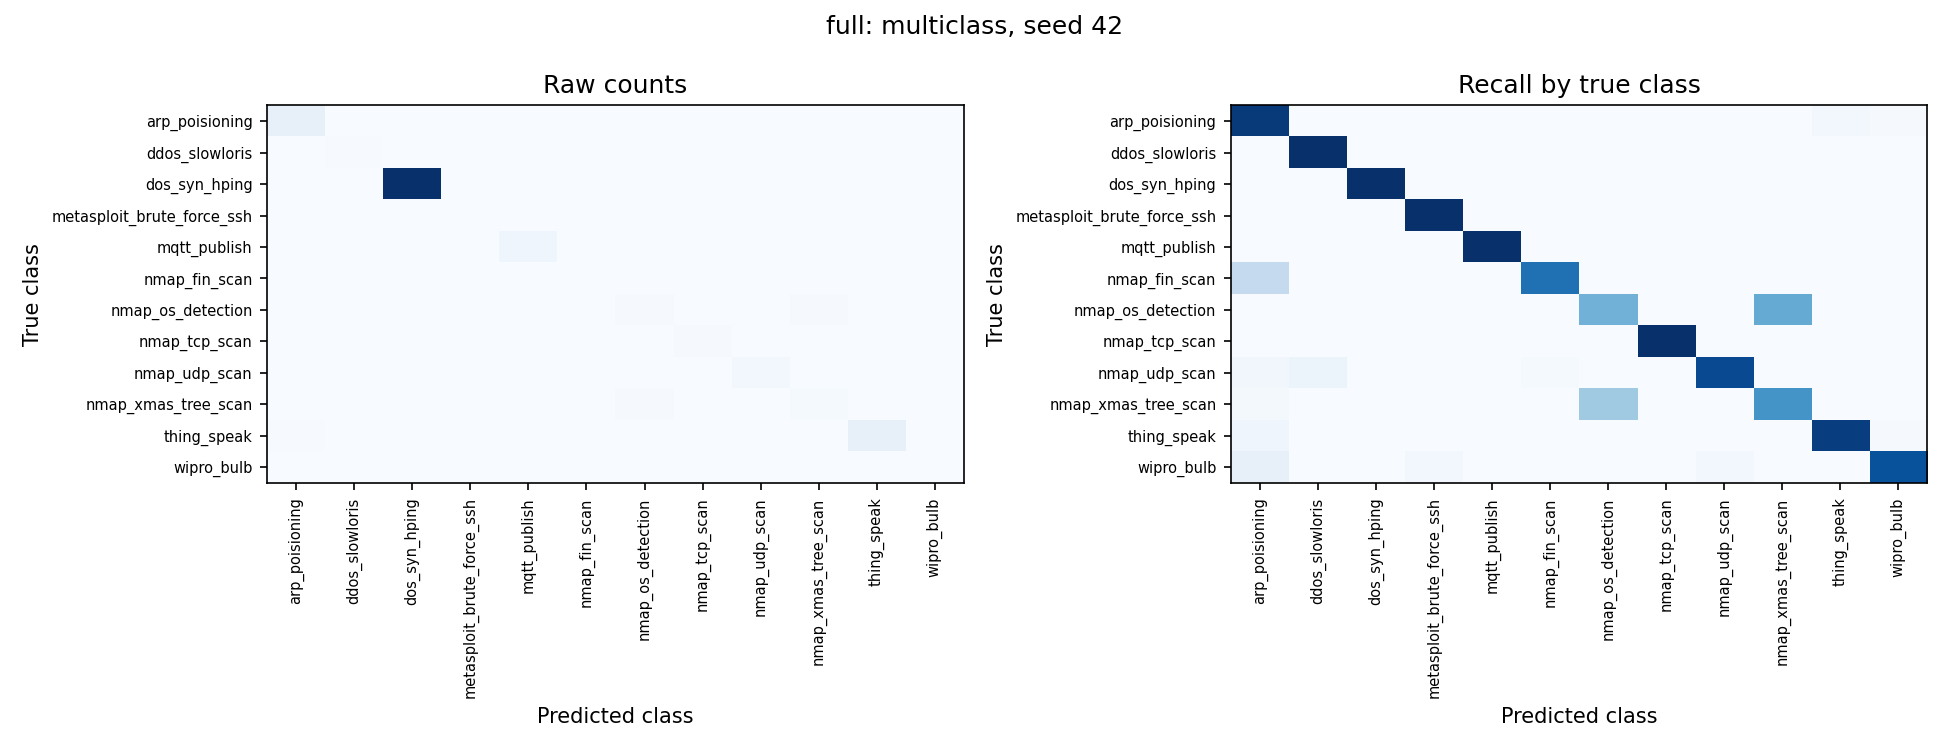

Across 5 seed(s), mean macro-F1 is 0.846598; seed 42 is 0.824796. Sample SD is 0.019463.


In [7]:
presentation.show_task(ROOT, RUN_MODE, "multiclass")

## 7. Baselines and seed variation

n=5, indicative only. Models share the fixed split and train-fitted features; instability and zero variance limit interpretation.

In [8]:
presentation.show_baselines(ROOT, RUN_MODE)

,task,model,n_seeds,macro_f1_mean,macro_f1_std,macro_f1_seed42,five_seed_complete
0,binary,bilstm,5,0.963204,0.008207,0.961016,True
1,binary,exlightnet,5,0.987069,0.00085,0.988054,True
2,binary,mlp,5,0.9869,0.000596,0.987123,True
3,binary,random_forest,5,0.993733,0.000168,0.993791,True
4,binary,std_cnn,5,0.979657,0.005668,0.977757,True
5,binary,xgboost,5,0.993371,0.0,0.993371,True
6,multiclass,bilstm,5,0.72821,0.028676,0.770176,True
7,multiclass,exlightnet,5,0.846598,0.019463,0.824796,True
8,multiclass,mlp,5,0.835599,0.010353,0.835454,True
9,multiclass,random_forest,5,0.8596,0.002888,0.859192,True


n=5, indicative only
Tiny multiclass test supports make macro-F1 comparisons noisy: metasploit_brute_force_ssh (test n=5), nmap_fin_scan (test n=4). Training seeds do not measure split or campaign variability.
Each model uses the same split and train-fitted forty features. Mean/sample-SD and seed-42 values use all completed runs; missing runs are flagged.


## 8. Paired ablations

n=5, indicative only. Cached paired tests replace SD-overlap comparisons. Differences use matched seeds and task-wide Holm correction.

In [9]:
presentation.show_ablations(ROOT, RUN_MODE)

,reference,model,n_pairs,sample_label,mean_difference,difference_sd,ci_low,ci_high,p_value,cohens_dz,p_holm,interpretation
6,exlightnet,balanced,5,"n=5, indicative only",0.040086,0.039720,-0.009234,0.089405,0.087005,1.009194,0.609032,inconclusive
10,exlightnet,no_sampler,5,"n=5, indicative only",0.001958,0.053311,-0.064237,0.068153,0.938490,0.036729,1.000000,inconclusive
11,exlightnet,no_se,5,"n=5, indicative only",0.019584,0.033123,-0.021544,0.060712,0.256679,0.591248,0.950318,inconclusive
13,exlightnet,standard_conv,5,"n=5, indicative only",-0.015281,0.013250,-0.031733,0.001171,0.061405,-1.153274,0.491242,inconclusive
15,exlightnet,top20,5,"n=5, indicative only",0.268743,0.019631,0.244367,0.293118,0.000007,13.689470,0.000075,difference supported


n=5, indicative only. ExLightNet minus variant on matched seeds; Holm correction uses the entire task family. Source: artifacts/stats_cpu_v1/paired_tests.csv.
Tiny multiclass test supports make macro-F1 comparisons noisy: metasploit_brute_force_ssh (test n=5), nmap_fin_scan (test n=4). Training seeds do not measure split or campaign variability.


## 9. Generated CPU statistics

n=5, indicative only. Paired tests, flow bootstrap uncertainty, per-class supports, post-hoc sensitivity and descriptive dynamics are loaded from generated CSVs.

In [10]:
presentation.show_statistics(ROOT, RUN_MODE)

n=5, indicative only. All tables are read from generated CPU statistics files.


Seed summaries — artifacts/stats_cpu_v1/model_summary.csv
All requested seeds contribute; sample SD uses ddof=1. Seed 42 is separate. Zero observed seed variance is flagged.
Tiny multiclass test supports make macro-F1 comparisons noisy: metasploit_brute_force_ssh (test n=5), nmap_fin_scan (test n=4). Training seeds do not measure split or campaign variability.


,task,model,n_seeds,sample_label,macro_f1_mean,macro_f1_sd,macro_f1_seed42,zero_seed_variance
0,binary,bilstm,5,"n=5, indicative only",0.963204,0.008207,0.961016,False
1,binary,exlightnet,5,"n=5, indicative only",0.987069,0.000850,0.988054,False
2,binary,exlightnet_w8,5,"n=5, indicative only",0.987042,0.000940,0.987762,False
3,binary,mlp,5,"n=5, indicative only",0.986900,0.000596,0.987123,False
4,binary,random_forest,5,"n=5, indicative only",0.993733,0.000168,0.993791,False
5,binary,std_cnn,5,"n=5, indicative only",0.979657,0.005668,0.977757,False
6,binary,xgboost,5,"n=5, indicative only",0.993371,0.000000,0.993371,True
7,multiclass,balanced,5,"n=5, indicative only",0.806513,0.030542,0.829804,False
8,multiclass,bilstm,5,"n=5, indicative only",0.728210,0.028676,0.770176,False
9,multiclass,exlightnet,5,"n=5, indicative only",0.846598,0.019463,0.824796,False


Paired comparisons — artifacts/stats_cpu_v1/paired_tests.csv
Differences are ExLightNet minus the comparison on matched seeds. Two-sided paired t tests, 95% t intervals and signed Cohen's dz use the paired differences. Holm adjustment includes all comparisons within each task, including ablations and W8. Wilcoxon is not used below six pairs. A constant model vector reduces the paired test to a one-sample test against that constant.
Tiny multiclass test supports make macro-F1 comparisons noisy: metasploit_brute_force_ssh (test n=5), nmap_fin_scan (test n=4). Training seeds do not measure split or campaign variability.


,task,reference,model,reference_device,comparison_device,device_label,n_pairs,sample_label,mean_difference,difference_sd,ci_low,ci_high,p_value,cohens_dz,p_holm,interpretation
0,binary,exlightnet,bilstm,cpu,cpu,cpu,5,"n=5, indicative only",0.023865,0.008368,0.013475,0.034255,0.003102,2.851956,0.012407,difference supported
1,binary,exlightnet,exlightnet_w8,cpu,cpu,cpu,5,"n=5, indicative only",0.000027,0.000261,-0.000297,0.000351,0.827661,0.103915,0.926878,practically equivalent
2,binary,exlightnet,mlp,cpu,cpu,cpu,5,"n=5, indicative only",0.000169,0.000467,-0.000411,0.000749,0.463439,0.362187,0.926878,practically equivalent
3,binary,exlightnet,random_forest,cpu,cpu,cpu,5,"n=5, indicative only",-0.006663,0.000873,-0.007747,-0.005580,0.000069,-7.636266,0.000414,difference supported
4,binary,exlightnet,std_cnn,cpu,cpu,cpu,5,"n=5, indicative only",0.007412,0.005987,-0.000022,0.014846,0.050413,1.238072,0.151239,inconclusive
5,binary,exlightnet,xgboost,cpu,cpu,cpu,5,"n=5, indicative only",-0.006301,0.000850,-0.007357,-0.005246,0.000078,-7.412340,0.000414,difference supported
6,multiclass,exlightnet,balanced,cpu,cpu,cpu,5,"n=5, indicative only",0.040086,0.039720,-0.009234,0.089405,0.087005,1.009194,0.609032,inconclusive
7,multiclass,exlightnet,bilstm,cpu,cpu,cpu,5,"n=5, indicative only",0.118388,0.037003,0.072443,0.164333,0.002020,3.199427,0.020201,difference supported
8,multiclass,exlightnet,exlightnet_w8,cpu,cpu,cpu,5,"n=5, indicative only",-0.000191,0.004470,-0.005741,0.005358,0.928286,-0.042844,1.000000,practically equivalent
9,multiclass,exlightnet,mlp,cpu,cpu,cpu,5,"n=5, indicative only",0.010999,0.014204,-0.006637,0.028636,0.158386,0.774394,0.950318,inconclusive


Flow bootstrap uncertainty — artifacts/stats_cpu_v1/flow_bootstrap.csv
Each replicate selects a training seed uniformly and resamples test flows. The estimand is single-random-run plus flow uncertainty; this is not a confidence interval for the seed mean. The pairing/method column identifies cached-prediction or UNPAIRED confusion-cell resampling.
Tiny multiclass test supports make macro-F1 comparisons noisy: metasploit_brute_force_ssh (test n=5), nmap_fin_scan (test n=4). Training seeds do not measure split or campaign variability.


... (11 outputs left out)

Binary epoch caps — artifacts/stats_cpu_v1/binary_caps.csv
Counts describe the recorded binary epoch cap and best-validation epoch; no uncapped local experiment was run.
Tiny multiclass test supports make macro-F1 comparisons noisy: metasploit_brute_force_ssh (test n=5), nmap_fin_scan (test n=4). Training seeds do not measure split or campaign variability.


,task,model,n_runs,n_epoch_observed,n_hit_cap,n_best_at_cap,sample_label
0,binary,bilstm,5,5,4.0,0.0,"n=5, indicative only"
1,binary,exlightnet,5,5,4.0,2.0,"n=5, indicative only"
2,binary,exlightnet_w8,5,0,NaN,NaN,"n=5, indicative only"
3,binary,mlp,5,5,1.0,0.0,"n=5, indicative only"
4,binary,random_forest,5,0,NaN,NaN,"n=5, indicative only"
5,binary,std_cnn,5,5,1.0,0.0,"n=5, indicative only"
6,binary,xgboost,5,0,NaN,NaN,"n=5, indicative only"


Per-seed observations — artifacts/stats_cpu_v1/per_seed_macro_f1.csv
All persisted seed observations are shown; missing values remain unavailable and no best seed is headlined.
Tiny multiclass test supports make macro-F1 comparisons noisy: metasploit_brute_force_ssh (test n=5), nmap_fin_scan (test n=4). Training seeds do not measure split or campaign variability.


,task,model,seed,n_seeds,sample_label,macro_f1,accuracy,epochs_run,best_epoch
0,binary,bilstm,42,5,"n=5, indicative only",0.961016,0.985380,20.0,16.0
1,binary,bilstm,43,5,"n=5, indicative only",0.955937,0.983268,14.0,8.0
2,binary,bilstm,44,5,"n=5, indicative only",0.963227,0.986301,20.0,18.0
3,binary,bilstm,45,5,"n=5, indicative only",0.977068,0.991607,20.0,19.0
4,binary,bilstm,46,5,"n=5, indicative only",0.958774,0.984405,20.0,18.0
5,binary,exlightnet,42,5,"n=5, indicative only",0.988054,0.995668,20.0,20.0
6,binary,exlightnet,43,5,"n=5, indicative only",0.987262,0.995343,20.0,17.0
7,binary,exlightnet,44,5,"n=5, indicative only",0.985706,0.994802,17.0,11.0
8,binary,exlightnet,45,5,"n=5, indicative only",0.987098,0.995289,20.0,18.0
9,binary,exlightnet,46,5,"n=5, indicative only",0.987226,0.995343,20.0,20.0


## 10. Weight-only quantisation

Per-channel INT8 storage is evaluated using dequantised floating-point weights.

In [11]:
presentation.show_quantization(ROOT, RUN_MODE)

,task,seed,pass,fp32_macro_f1,w8_macro_f1,delta,fp32_bytes,max_abs_weight_error,int8_bytes,quantized_weight_tensors,compute,size_breakdown
0,binary,42,True,0.988054,0.987762,-0.000293,152312,0.002242,48877,10,FP32 with dequantized W8 weights,"{'weights_only_int8_bytes': 34560, 'scales_fp3..."
1,binary,43,True,0.987262,0.987552,0.000290,152312,0.002090,49694,10,FP32 with dequantized W8 weights,"{'weights_only_int8_bytes': 34560, 'scales_fp3..."
2,binary,44,True,0.985706,0.985415,-0.000291,152312,0.002098,50446,10,FP32 with dequantized W8 weights,"{'weights_only_int8_bytes': 34560, 'scales_fp3..."
3,binary,45,True,0.987098,0.987111,0.000012,152312,0.002102,49403,10,FP32 with dequantized W8 weights,"{'weights_only_int8_bytes': 34560, 'scales_fp3..."
4,binary,46,True,0.987226,0.987371,0.000146,152312,0.002319,49892,10,FP32 with dequantized W8 weights,"{'weights_only_int8_bytes': 34560, 'scales_fp3..."
5,multiclass,42,True,0.824796,0.825307,0.000511,163832,0.002410,55271,10,FP32 with dequantized W8 weights,"{'weights_only_int8_bytes': 37440, 'scales_fp3..."
6,multiclass,43,True,0.855791,0.851614,-0.004177,163832,0.002304,53843,10,FP32 with dequantized W8 weights,"{'weights_only_int8_bytes': 37440, 'scales_fp3..."
7,multiclass,44,True,0.873419,0.869331,-0.004088,163832,0.002149,52876,10,FP32 with dequantized W8 weights,"{'weights_only_int8_bytes': 37440, 'scales_fp3..."
8,multiclass,45,True,0.831274,0.837595,0.006321,163832,0.002302,53206,10,FP32 with dequantized W8 weights,"{'weights_only_int8_bytes': 37440, 'scales_fp3..."
9,multiclass,46,True,0.847711,0.850102,0.002391,163832,0.002550,53706,10,FP32 with dequantized W8 weights,"{'weights_only_int8_bytes': 37440, 'scales_fp3..."


Tiny multiclass test supports make macro-F1 comparisons noisy: metasploit_brute_force_ssh (test n=5), nmap_fin_scan (test n=4). Training seeds do not measure split or campaign variability.
Artifact sizes and metric changes are measured. Weight-only quantisation retains floating-point compute and does not establish an INT8 compute speedup.


## 11. Measured latency

Timing comes from persisted isolated CPU benchmark evidence. Eager batch-one timing includes framework dispatch; the dispatch fraction is NOT MEASURED.

In [12]:
presentation.show_latency(ROOT, RUN_MODE)

,task,model,seed,params,serialized_bytes,latency_mean_ms,latency_median_ms,latency_p95_ms,peak_rss_bytes
0,binary,exlightnet,42,35438.0,152312,0.617452,0.611172,0.652839,356163584
1,binary,exlightnet,43,35438.0,152312,0.621183,0.610853,0.660367,358146048
2,binary,exlightnet,44,35438.0,152312,0.605431,0.603468,0.621167,358146048
3,binary,exlightnet,45,35438.0,152312,0.605364,0.602642,0.631744,358146048
4,binary,exlightnet,46,35438.0,152312,0.603331,0.603034,0.630098,358146048
...,...,...,...,...,...,...,...,...,...
90,multiclass,exlightnet_w8,42,38328.0,55271,0.593708,0.592135,0.630522,616890368
91,multiclass,exlightnet_w8,43,38328.0,53843,0.592138,0.591728,0.612191,616890368
92,multiclass,exlightnet_w8,44,38328.0,52876,0.599908,0.590700,0.644268,616890368
93,multiclass,exlightnet_w8,45,38328.0,53206,0.592982,0.591298,0.622789,616890368


Measurements use one thread and batch one after 100 warmups, with 1000 timed inferences. Peak RSS is the whole process peak; no Raspberry Pi or multi-core throughput is inferred. Eager batch-one latency includes framework dispatch overhead; it is not pure compute or hardware-independent. The dispatch fraction is NOT MEASURED.


## 12. SHAP and faithfulness

Attributions explain FP32 logits; deletion measures predicted-class probabilities. The actual method, fallback and residuals remain visible.

,method,fallback_reason,additivity_max_abs,additivity_mean_abs
0,GradientExplainer,AssertionError: The SHAP explanations do not s...,2.1547,0.221882


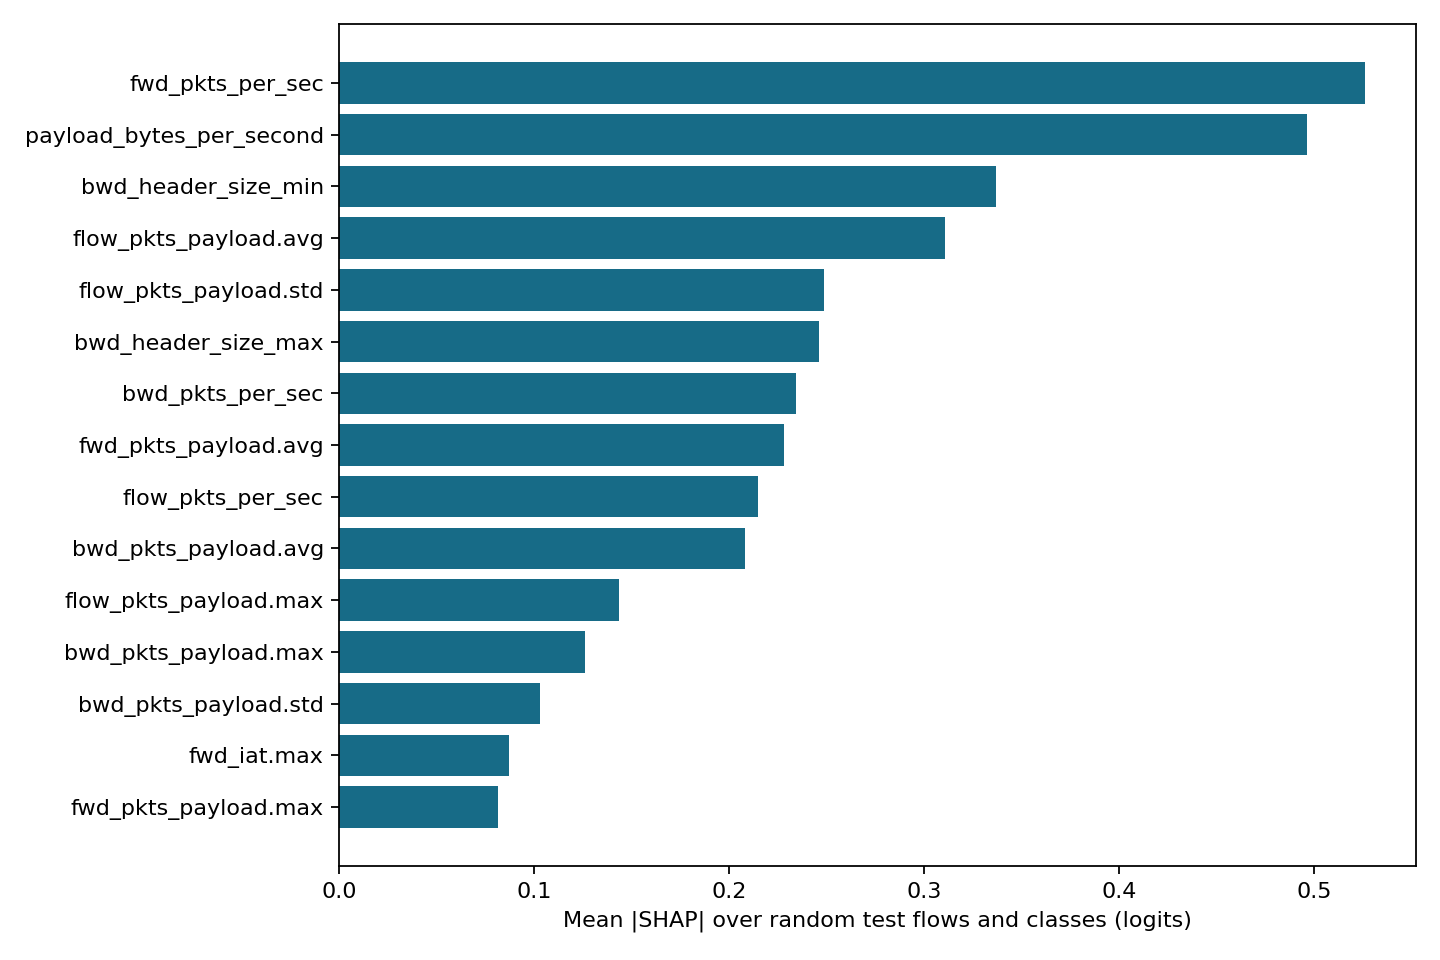

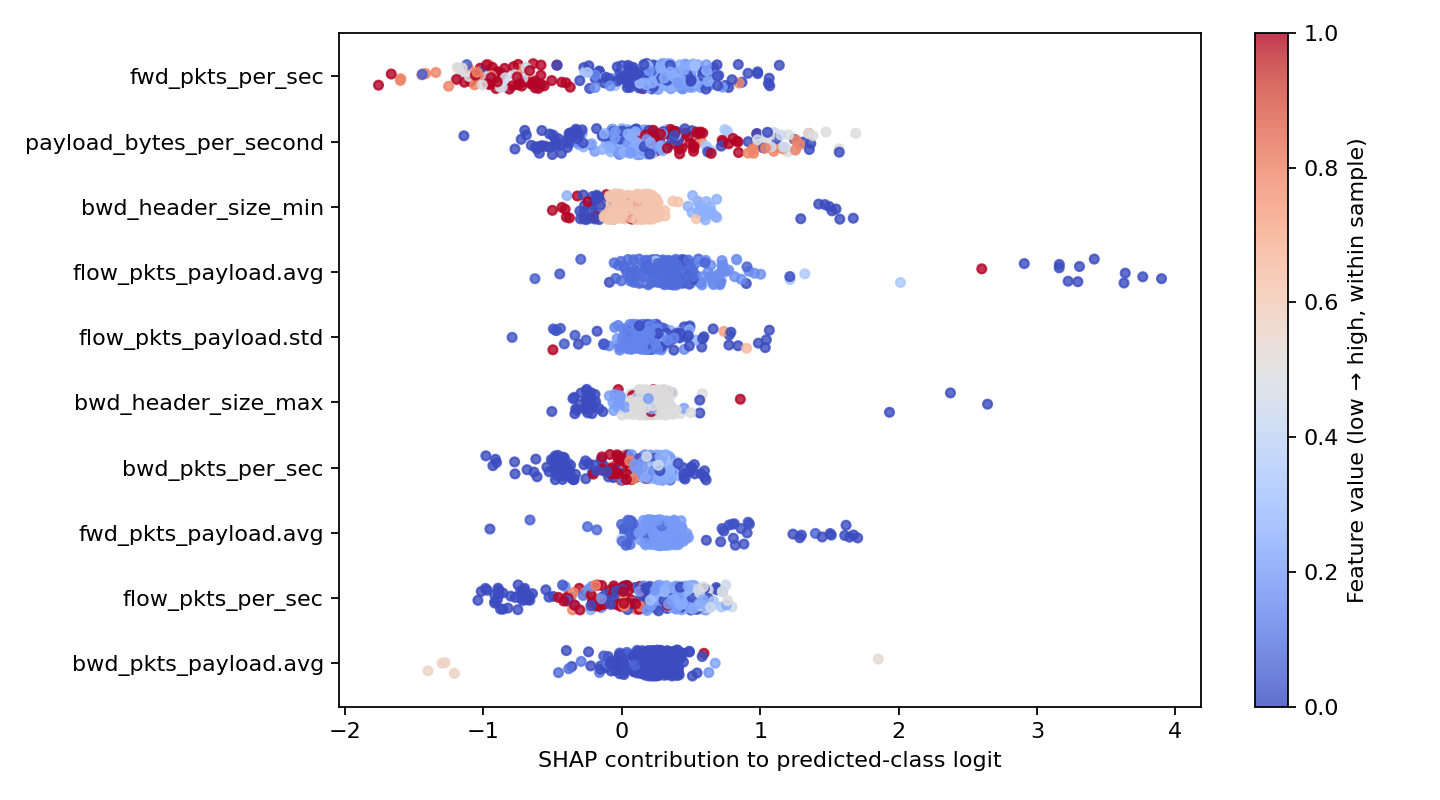

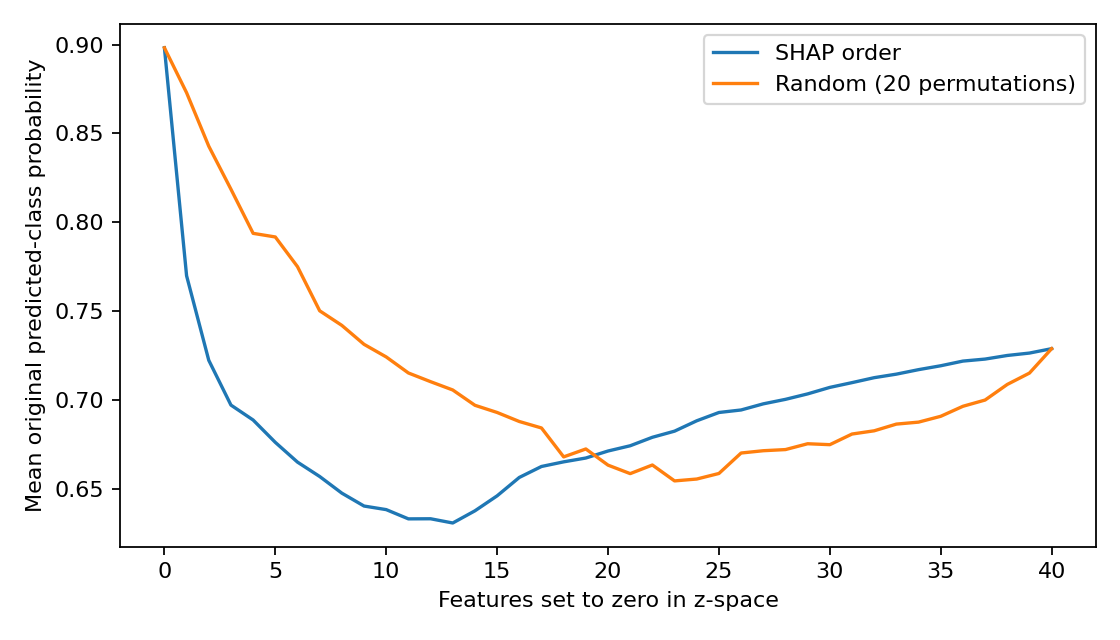

,spearman_top15_fp32_feature_set,top5_overlap
0,1.0,5


,true_class,predicted_class,correct,test_position,probability,top5
0,dos_syn_hping,dos_syn_hping,True,0,0.944329,"[{'feature': 'fwd_pkts_per_sec', 'signed_logit..."
1,nmap_os_detection,nmap_xmas_tree_scan,False,44,0.357215,"[{'feature': 'flow_pkts_payload.avg', 'signed_..."


SHAP explains FP32 logits using 200 train backgrounds and 300 random test flows. Deletion-AUC is 0.687726, versus 0.711405 for random ordering; lower means less retained original-class probability under this masking protocol.
DeepExplainer failed its additivity check. The fallback's displayed residuals limit additive-efficiency claims; these attributions are approximate diagnostics.


In [13]:
presentation.show_shap(ROOT, RUN_MODE)

## Stratified SHAP final analysis — dated amendment 2026-11-18

This separate, CPU-only final analysis reuses the cached seed-42 FP32 checkpoint and exact prior training background. The saved per-class rankings, balanced global rankings, earlier-sample composition and deletion curves are loaded without new model queries.

final analysis; no selection use
Per-class rankings target each true class’s own logit; the primary global ranking weights classes equally. The auxiliary all-output ranking preserves the earlier output-averaging definition. Deletion follows the original predicted class even when it is incorrect; this is final analysis, never selection.


,sample_size,background_size,method,fallback_reason,warnings,additivity_max_abs,additivity_mean_abs,nsamples_gradient
0,259,200,GradientExplainer,AssertionError: The SHAP explanations do not s...,[unrecognized nn.Module: AdaptiveMaxPool1d],3.337002,0.296647,200


Additivity residuals summarize 259 flows by 12 output logits. Separate output-logit summaries were not retained. These are approximate attributions, not exact SHAP.
Recorded warnings: unrecognized nn.Module: AdaptiveMaxPool1d
earlier_random300_class_composition.csv


,class_index,true_class,test_support,sampled_count,test_fraction,sample_fraction
0,0,arp_poisioning,1162,16,0.062920,0.053333
1,1,ddos_slowloris,80,0,0.004332,0.000000
2,2,dos_syn_hping,14199,232,0.768843,0.773333
3,3,metasploit_brute_force_ssh,5,0,0.000271,0.000000
4,4,mqtt_publish,622,11,0.033680,0.036667
5,5,nmap_fin_scan,4,0,0.000217,0.000000
6,6,nmap_os_detection,300,6,0.016244,0.020000
7,7,nmap_tcp_scan,151,3,0.008176,0.010000
8,8,nmap_udp_scan,389,3,0.021063,0.010000
9,9,nmap_xmas_tree_scan,302,5,0.016353,0.016667


per_class_top10.csv


,class_index,true_class,test_support,sampled_count,predicted_correct_count,rank,feature_index,feature,mean_abs_phi
0,0,arp_poisioning,1162,25,25,1,38,bwd_header_size_min,0.668492
1,0,arp_poisioning,1162,25,25,2,5,fwd_pkts_payload.tot,0.512906
2,0,arp_poisioning,1162,25,25,3,6,flow_pkts_payload.avg,0.423809
3,0,arp_poisioning,1162,25,25,4,2,fwd_subflow_bytes,0.350780
4,0,arp_poisioning,1162,25,25,5,4,flow_pkts_payload.std,0.314975
...,...,...,...,...,...,...,...,...,...
115,11,wipro_bulb,38,25,22,6,6,flow_pkts_payload.avg,0.256236
116,11,wipro_bulb,38,25,22,7,38,bwd_header_size_min,0.228758
117,11,wipro_bulb,38,25,22,8,13,flow_iat.tot,0.223084
118,11,wipro_bulb,38,25,22,9,4,flow_pkts_payload.std,0.218668


... (2 outputs left out)

balanced_global_all_outputs_ranking.csv


,rank,feature_index,feature,mean_abs_phi
0,1,6,flow_pkts_payload.avg,0.861266
1,2,0,fwd_pkts_payload.avg,0.593490
2,3,22,fwd_pkts_per_sec,0.463701
3,4,21,payload_bytes_per_second,0.450527
4,5,4,flow_pkts_payload.std,0.412692
5,6,38,bwd_header_size_min,0.391064
6,7,37,bwd_header_size_max,0.366151
7,8,7,flow_pkts_payload.max,0.323390
8,9,23,flow_pkts_per_sec,0.257967
9,10,11,bwd_pkts_payload.avg,0.228500


early_deletion_k10.csv


,class_index,true_class,test_support,sampled_count,predicted_correct_count,original_mean_probability,shap_k10,random_k10,shap_drop_k10,random_drop_k10,random_minus_shap_k10,shap_normalized_auc,random_normalized_auc
0,0,arp_poisioning,1162,25,25,0.754687,0.112235,0.466270,0.642451,0.288417,0.354034,0.101828,0.287624
1,1,ddos_slowloris,80,25,25,0.759762,0.006222,0.228697,0.753540,0.531065,0.222475,0.022260,0.146352
2,2,dos_syn_hping,14199,25,25,0.952105,0.814854,0.873579,0.137251,0.078525,0.058726,0.883920,0.873606
3,3,metasploit_brute_force_ssh,5,5,5,0.783789,0.046305,0.307677,0.737484,0.476112,0.261372,0.067237,0.189045
4,4,mqtt_publish,622,25,25,0.844703,0.013195,0.274005,0.831508,0.570698,0.260811,0.023174,0.191984
5,5,nmap_fin_scan,4,4,3,0.361102,0.031163,0.145714,0.329939,0.215388,0.114551,0.023994,0.094137
6,6,nmap_os_detection,300,25,15,0.422505,0.000065,0.008633,0.422440,0.413872,0.008568,0.008096,0.025819
7,7,nmap_tcp_scan,151,25,25,0.959633,0.303416,0.744231,0.656217,0.215402,0.440815,0.251821,0.593070
8,8,nmap_udp_scan,389,25,21,0.630436,0.000592,0.140676,0.629844,0.489760,0.140084,0.013076,0.112315
9,9,nmap_xmas_tree_scan,302,25,16,0.417548,0.000174,0.053371,0.417374,0.364178,0.053196,0.008807,0.045216


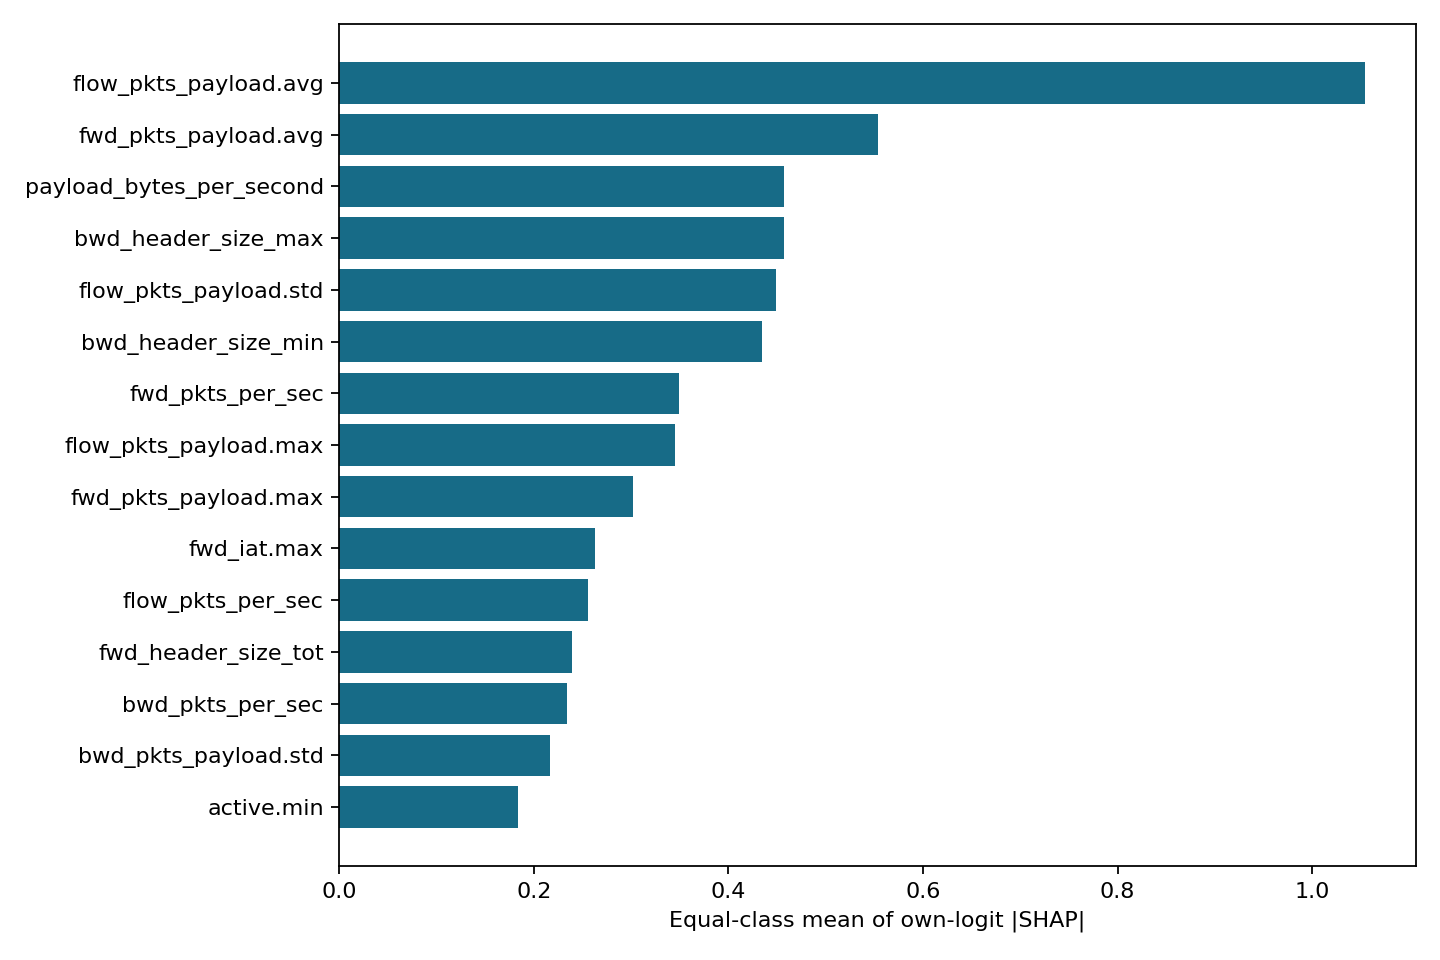

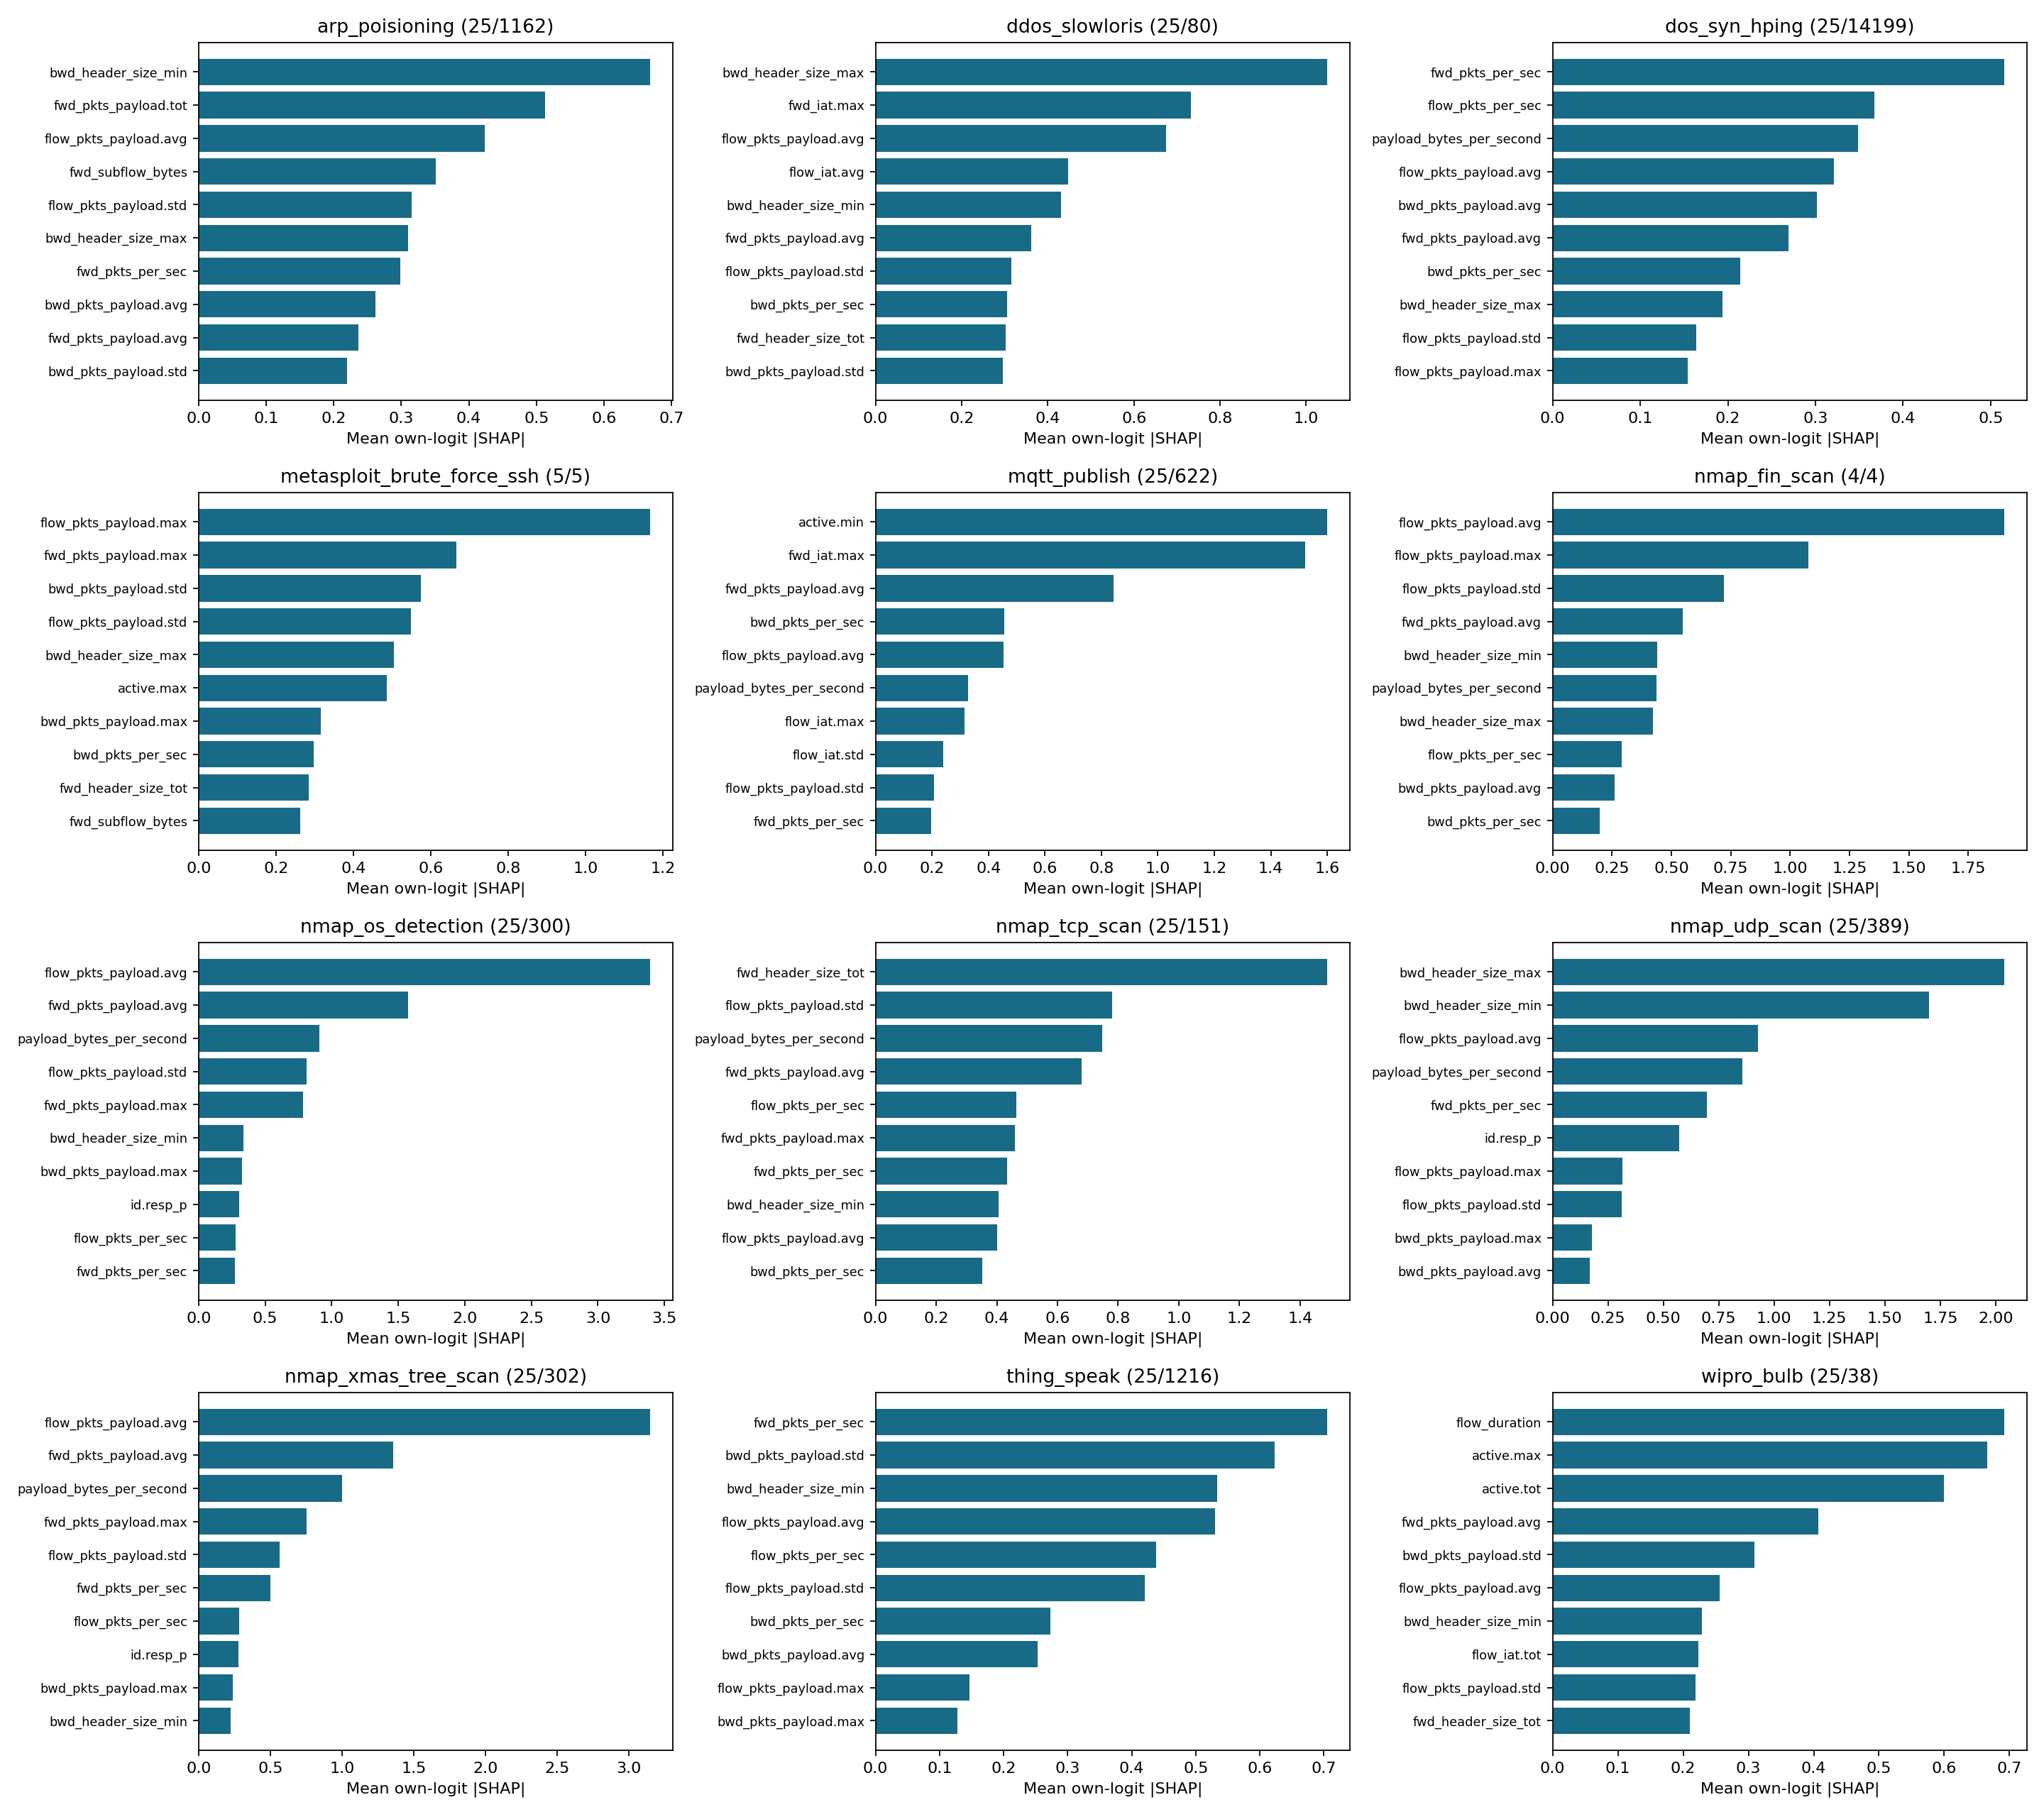

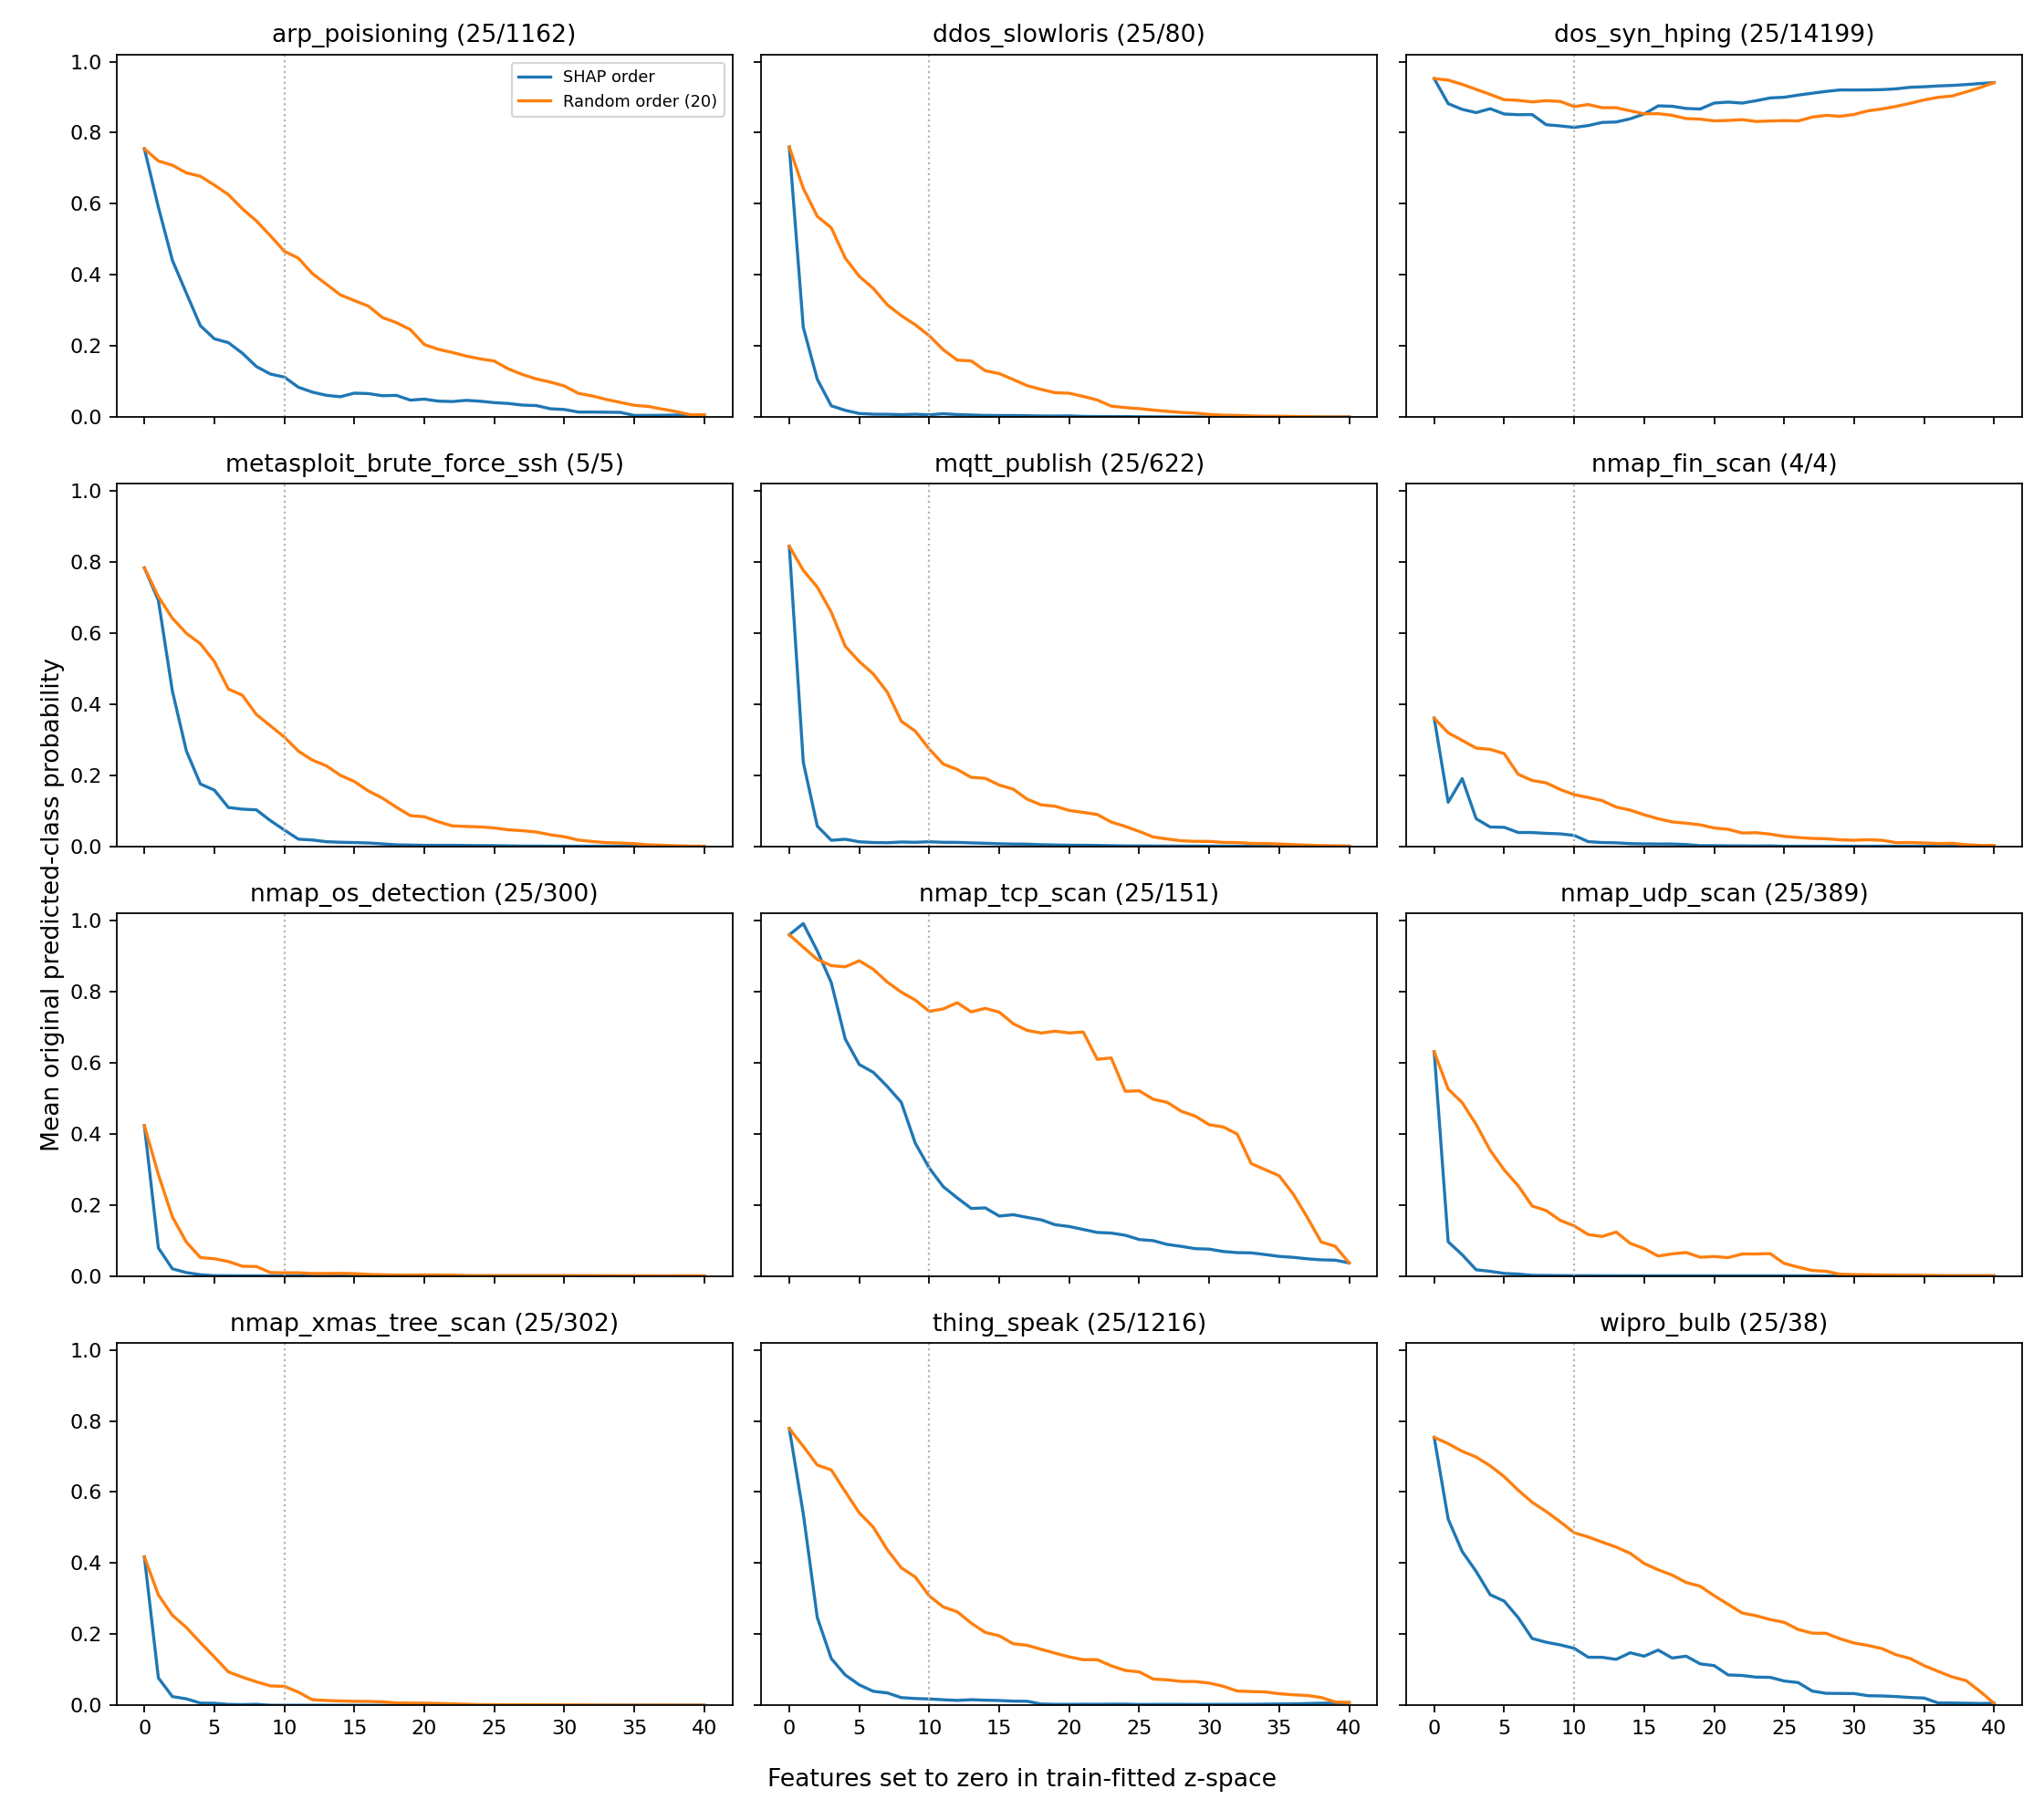

Random-minus-SHAP at k=10 is a descriptive probability contrast on the same flows. Small class supports and measured additivity residuals limit interpretation; no monotonicity, significance, causal effect or model-selection conclusion is implied.


In [14]:
presentation.show_final_analysis(ROOT)

## 13. Ours versus paper (quoted)

n=5, indicative only. Paper headlines are quotations, never optimization targets; rare-class supports limit macro-F1 comparisons.

In [15]:
presentation.show_comparison(ROOT, RUN_MODE)

,task,model,n_seeds,ours_mean_macro_f1,ours_sample_std,ours_seed42_macro_f1,paper_quoted_macro_f1,sample_label
0,binary,bilstm,5,0.963204,0.008207,0.961016,0.9354,"n=5, indicative only"
1,binary,exlightnet,5,0.987069,0.000850,0.988054,0.9860,"n=5, indicative only"
2,binary,exlightnet_w8,5,0.987042,0.000940,0.987762,0.9860,"n=5, indicative only"
3,binary,mlp,5,0.986900,0.000596,0.987123,0.9800,"n=5, indicative only"
4,binary,random_forest,5,0.993733,0.000168,0.993791,0.9934,"n=5, indicative only"
5,binary,std_cnn,5,0.979657,0.005668,0.977757,0.9820,"n=5, indicative only"
6,binary,xgboost,5,0.993371,0.000000,0.993371,0.9957,"n=5, indicative only"
7,multiclass,balanced,5,0.806513,0.030542,0.829804,0.7807,"n=5, indicative only"
8,multiclass,bilstm,5,0.728210,0.028676,0.770176,0.6380,"n=5, indicative only"
9,multiclass,exlightnet,5,0.846598,0.019463,0.824796,0.8621,"n=5, indicative only"


Tiny multiclass test supports make macro-F1 comparisons noisy: metasploit_brute_force_ssh (test n=5), nmap_fin_scan (test n=4). Training seeds do not measure split or campaign variability.
Paper columns are labelled quotations from PAPER_REPORTED. Agreement with a paper number is not a training objective. Single-seed demonstrations do not estimate full-recipe performance.


## 14. Limitations and dated stopping rule

Fixed split, small seed count, rare-class supports, unstable baselines and hardware-specific eager timing constrain conclusions. The dated primary/secondary stopping rule is loaded verbatim; it never establishes causality.

In [16]:
presentation.show_limitations(ROOT)
presentation.show_stopping_hypothesis_declaration(ROOT)
display(pd.DataFrame(read_json(ROOT / "results" / RUN_MODE / "failures.json")))

The class-stratified flow split is fixed. The five canonical seeds vary initialization and sampling, not the split; n=5, indicative only. Related attack-run flows can cross partitions because session/campaign identifiers are absent. A clustering PROXY is not campaign-disjoint validation.
Tiny multiclass test supports make macro-F1 comparisons noisy: metasploit_brute_force_ssh (test n=5), nmap_fin_scan (test n=4). Training seeds do not measure split or campaign variability.
The relation between epochs run and macro-F1 is descriptive. The dated stopping-rule hypothesis uses predeclared primary and secondary endpoints; even a supported result never establishes causality. See the effective declaration and Stage B report.
The persisted training-dynamics table flags std_cnn instability (early best-validation epochs or large seed SD). This baseline cannot establish that ExLightNet is superior. Zero observed seed variance, including XGBoost under the paper configuration, is flagged in the gene

""


## Fast demonstration (historical)

This optional reduced-run evidence is separate from the full reproduction. It is read from its existing cache, with no live training.

In [17]:
presentation.show_fast_demonstration(ROOT)

,task,model,n_seeds,macro_f1_mean,macro_f1_std,macro_f1_seed42
0,binary,bilstm,1,0.945036,None,0.945036
1,binary,exlightnet,1,0.962673,None,0.962673
2,binary,exlightnet_w8,1,0.962386,None,0.962386
3,binary,mlp,1,0.94093,None,0.94093
4,binary,random_forest,1,0.993791,None,0.993791
5,binary,std_cnn,1,0.863285,None,0.863285
6,binary,xgboost,1,0.993371,None,0.993371
7,multiclass,balanced,1,0.477435,None,0.477435
8,multiclass,bilstm,1,0.468787,None,0.468787
9,multiclass,exlightnet,1,0.58366,None,0.58366


Historical reduced training and SHAP evidence. A single seed cannot estimate seed variation; this scope remains separate from the full reproduction.
Tiny multiclass test supports make macro-F1 comparisons noisy: metasploit_brute_force_ssh (test n=5), nmap_fin_scan (test n=4). Training seeds do not measure split or campaign variability.
